# Defining the Problem

## Estimating diffusion parameteres of two different species in a reaction diffusion setup.

![image.png](attachment:image.png)

### Here r_u and r_v (diffusion coefficients) are needed to be infered using the sparse data available (exported from comsol), the above governing system and some initial and boundary conditions

## Domain -

### The space is taken as two dimensional, x and y both range between 0 and 1.
### t ranges from 0 to 3000 seconds

## Initial conditions -

### u(x,y,t) = 0.5 for 0.45<=x<=0.55 and 0.45<=y<=0.55
### else 1

### v(x,y,t) = 0.25 for 0.45<=x<=0.55 and 0.45<=y<=0.55
### else 0

### $\frac{\partial u}{\partial t} = 0$ $\frac{\partial v}{\partial t} = 0$

## Boundary Conditions -

### Zero flux (both for u and v)

# Importing Libraries

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import torch.optim as optim
import pandas as pd

In [3]:
# Step 1: Define problem

L = 1.0  # length of the domain
x_min, x_max = 0.0, L
y_min, y_max = 0.0, L
t_min, t_max = 0.0, 3000.0

# dimensionality
input_dim = 3   # (x, y, t)
output_dim = 1  # C only
F = 0.037
k = 0.06

Mounting The drive for data

In [4]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


Importing Data

In [5]:
import pandas as pd

# Path to the file in Google Drive
file_path = "/content/drive/MyDrive/gray_scott_data/data.txt"

# Generate column names
times = range(0, 3001, 10)

columns = ["x", "y"]

for t in times:
    columns += [f"u_{t}", f"v_{t}"]

# Read the data
df = pd.read_csv(
    file_path,
    sep=r"\s+",
    comment="%",
    header=None,
    names=columns
)

# Display the DataFrame
print(df)

              x         y  u_0           v_0  u_10          v_10  u_20  \
0      0.000000  0.000000  1.0  6.044687e-78   1.0  2.204048e-58   1.0   
1      0.001818  0.000000  1.0  1.862587e-77   1.0  2.288148e-58   1.0   
2      0.000000  0.001818  1.0  1.862587e-77   1.0  2.288148e-58   1.0   
3      0.001818  0.001818  1.0  6.161572e-77   1.0  2.375532e-58   1.0   
4      0.000000  0.003970  1.0  9.483544e-77   1.0  2.614471e-58   1.0   
...         ...       ...  ...           ...   ...           ...   ...   
10196  0.993544  0.993544  1.0  6.523927e-74   1.0  5.084951e-58   1.0   
10197  0.996030  0.990724  1.0  6.075878e-74   1.0  5.649834e-58   1.0   
10198  0.993544  0.996030  1.0  1.106928e-74   1.0  3.970411e-58   1.0   
10199  0.996030  0.993544  1.0  1.106928e-74   1.0  3.970411e-58   1.0   
10200  0.996030  0.996030  1.0  1.961715e-75   1.0  3.103192e-58   1.0   

               v_20  u_30          v_30  ...    u_2960    v_2960    u_2970  \
0      3.249821e-46   1.0  2.4514

In [6]:
print(df.shape)
df.head()

(10201, 604)


,x,y,u_0,v_0,u_10,v_10,u_20,v_20,u_30,v_30,...,u_2960,v_2960,u_2970,v_2970,u_2980,v_2980,u_2990,v_2990,u_3000,v_3000
0,0.000000,0.000000,1.0,6.044687e-78,1.0,2.204048e-58,1.0,3.249821e-46,1.0,2.451408e-44,...,0.768147,0.021323,0.767991,0.021332,0.767909,0.021328,0.767634,0.021364,0.767335,0.021405
1,0.001818,0.000000,1.0,1.862587e-77,1.0,2.288148e-58,1.0,3.325602e-46,1.0,2.507647e-44,...,0.767807,0.021465,0.767650,0.021475,0.767568,0.021470,0.767293,0.021506,0.766994,0.021548
2,0.000000,0.001818,1.0,1.862587e-77,1.0,2.288148e-58,1.0,3.325602e-46,1.0,2.507647e-44,...,0.767807,0.021465,0.767650,0.021475,0.767568,0.021470,0.767293,0.021506,0.766994,0.021548
3,0.001818,0.001818,1.0,6.161572e-77,1.0,2.375532e-58,1.0,3.403211e-46,1.0,2.565221e-44,...,0.767467,0.021607,0.767310,0.021617,0.767228,0.021612,0.766952,0.021649,0.766653,0.021691
4,0.000000,0.003970,1.0,9.483544e-77,1.0,2.614471e-58,1.0,3.616293e-46,1.0,2.723311e-44,...,0.766520,0.022006,0.766363,0.022016,0.766281,0.022011,0.766004,0.022048,0.765703,0.022090


Shifting to GPU

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Using device: cpu


## Sampling sparse data from imported data

!! Data sampling stratergy can be different, currenlty using uniformly random

In [8]:
# Separate u and v columns
u_df = df[["x", "y"] + [col for col in df.columns if col.startswith("u_")]]
v_df = df[["x", "y"] + [col for col in df.columns if col.startswith("v_")]]

# Randomly sample 1000 data points from each
u_sample = u_df.sample(n=1000, random_state=42)
v_sample = v_df.sample(n=1000, random_state=42)

print("u_df shape:", u_df.shape)
print("v_df shape:", v_df.shape)

print("u_sample shape:", u_sample.shape)
print("v_sample shape:", v_sample.shape)

u_df shape: (10201, 303)
v_df shape: (10201, 303)
u_sample shape: (1000, 303)
v_sample shape: (1000, 303)


In [9]:
u_sample.head()

,x,y,u_0,u_10,u_20,u_30,u_40,u_50,u_60,u_70,...,u_2910,u_2920,u_2930,u_2940,u_2950,u_2960,u_2970,u_2980,u_2990,u_3000
5135,0.763673,0.188312,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,...,0.393441,0.391778,0.390062,0.388295,0.386477,0.384609,0.382690,0.380720,0.378677,0.376575
7921,0.993544,0.223822,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,...,0.702996,0.702442,0.701922,0.701435,0.700981,0.700559,0.700170,0.699814,0.699476,0.699166
1087,0.108312,0.015918,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,...,0.348280,0.348762,0.349267,0.349801,0.350365,0.350957,0.351579,0.352230,0.352809,0.353381
4826,0.211651,0.696141,1.0,1.0,1.0,1.0,1.0,1.0,0.999999,0.999999,...,0.586871,0.586378,0.585814,0.585178,0.584468,0.583686,0.582830,0.581902,0.581214,0.580568
10060,0.984082,0.944156,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,1.000000,...,0.425550,0.425485,0.425423,0.425388,0.425381,0.425402,0.425450,0.425526,0.425361,0.425125


## Sampling Collocation points

!! Collocation points stratergy can be changed, currently using uniformly random

Normalizing everything from -1 to 1

In [10]:
def normalize(x, xmin, xmax):
    return 2.0 * (x - xmin) / (xmax - xmin) - 1.0

In [11]:
sx = 2.0 / (x_max - x_min)
sy = 2.0 / (y_max - y_min)
st = 2.0 / (t_max - t_min)

In [12]:
N_collocation = 10000

# Domain limits
x_min, x_max = df["x"].min(), df["x"].max()
y_min, y_max = df["y"].min(), df["y"].max()
t_min, t_max = 0, 3000

# Random collocation points
x_col = np.random.uniform(x_min, x_max, N_collocation)
y_col = np.random.uniform(y_min, y_max, N_collocation)
t_col = np.random.uniform(t_min, t_max, N_collocation)

# Put them into a dataframe
collocation_df = pd.DataFrame({
    "x": x_col,
    "y": y_col,
    "t": t_col
})


In [13]:
print(collocation_df.shape)
collocation_df.head()

(10000, 3)


,x,y,t
0,0.307512,0.795641,2751.827342
1,0.110583,0.831663,216.434951
2,0.321912,0.261448,1605.523620
3,0.444769,0.280152,2521.141141
4,0.956207,0.619463,536.594193


Defining gradients

In [14]:
def gradients(C, x):
    return torch.autograd.grad(
        C,
        x,
        grad_outputs=torch.ones_like(C),
        create_graph=True,
        retain_graph=True
    )[0]

## Defining model for u(x,y,t) and v(x,y,t)

!! Hyperparameters have been chosen arbitrarily currently, can be optimized

Currently we use different NNs for u and v even though we have coupled PDEs, will making a larger unified NN help ?

In [15]:
class u_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self, X):
        # xt = torch.cat([x, y, t], dim=-1)
        return self.network(X)


In [16]:
class v_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,64),
            nn.Tanh(),
            nn.Linear(64,1)
        )

    def forward(self, X):
        # xt = torch.cat([x, y, t], dim=-1)
        return self.network(X)


NN for $D_u = D_u(x,y)$

!! Hyperparameters have been chosen arbitrarily currently, can be optimized

also Dv is considered constant currently

In [17]:
D_SCALE = 1e-5   # characteristic magnitude of the diffusion coefficients

class Du_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2,32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,32),
            nn.Tanh(),
            nn.Linear(32,1)
        )

    def forward(self, X):
        # network output is O(1); scale it and keep it positive
        return D_SCALE * torch.nn.functional.softplus(self.network(X))


class Dv_net(nn.Module):
    def __init__(self):
        super().__init__()
        self.Dv_raw = nn.Parameter(torch.tensor(1.0))   # O(1) parameter -> Dv about 1.3e-5 at init

    def value(self):
        return D_SCALE * torch.nn.functional.softplus(self.Dv_raw)

    def forward(self, X):
        return self.value() * torch.ones_like(X[:, 0:1])   # shape (N,1)

# Defining different Losses

## Data Loss

![image.png](attachment:image.png)

In [18]:
times = np.arange(0, 3001, 10)

# u data
x_u = np.repeat(u_sample["x"].values, len(times))
y_u = np.repeat(u_sample["y"].values, len(times))
t_u = np.tile(times, len(u_sample))

u_true = u_sample[
    [f"u_{t}" for t in times]
].values.flatten()

# v data
x_v = np.repeat(v_sample["x"].values, len(times))
y_v = np.repeat(v_sample["y"].values, len(times))
t_v = np.tile(times, len(v_sample))

v_true = v_sample[
    [f"v_{t}" for t in times]
].values.flatten()

In [19]:
X_u = torch.tensor(
    np.column_stack([x_u, y_u, t_u]),
    dtype=torch.float32
)

U_true = torch.tensor(
    u_true.reshape(-1, 1),
    dtype=torch.float32
)

X_v = torch.tensor(
    np.column_stack([x_v, y_v, t_v]),
    dtype=torch.float32
)

V_true = torch.tensor(
    v_true.reshape(-1, 1),
    dtype=torch.float32
)

In [20]:
X_u, U_true = X_u.to(device), U_true.to(device)
X_v, V_true = X_v.to(device), V_true.to(device)

In [21]:
def data_loss(u_net,
        v_net,
        X_u,
        U_true,
        X_v,
        V_true,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max):

    # Normalize inputs
    X_u_norm = X_u.clone()
    X_v_norm = X_v.clone()

    X_u_norm[:, 0] = normalize(X_u[:, 0], x_min, x_max)
    X_u_norm[:, 1] = normalize(X_u[:, 1], y_min, y_max)
    X_u_norm[:, 2] = normalize(X_u[:, 2], t_min, t_max)

    X_v_norm[:, 0] = normalize(X_v[:, 0], x_min, x_max)
    X_v_norm[:, 1] = normalize(X_v[:, 1], y_min, y_max)
    X_v_norm[:, 2] = normalize(X_v[:, 2], t_min, t_max)

    # Predictions
    U_pred = u_net(X_u_norm)
    V_pred = v_net(X_v_norm)

    # MSE
    loss_u = torch.mean((U_pred - U_true) ** 2)
    loss_v = torch.mean((V_pred - V_true) ** 2)

    return loss_u + loss_v

PDE loss

In [22]:
def pde_loss(
    u_net, v_net, Du_net,
    X_col,
    Dv_net, F, k,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max,
    return_terms=False
):

    # --------------------------------------------------
    # Normalization factors
    # --------------------------------------------------

    sx = 2.0 / (x_max - x_min)
    sy = 2.0 / (y_max - y_min)
    st = 2.0 / (t_max - t_min)

    # --------------------------------------------------
    # Normalize collocation points
    # --------------------------------------------------

    X_raw = X_col.clone().requires_grad_(True)

    x = normalize(X_raw[:, 0:1], x_min, x_max)
    y = normalize(X_raw[:, 1:2], y_min, y_max)
    t = normalize(X_raw[:, 2:3], t_min, t_max)

    X = torch.cat([x, y, t], dim=1)

    # --------------------------------------------------
    # Network predictions
    # --------------------------------------------------

    u = u_net(X)
    v = v_net(X)

    # D = D(x,y)
    D = Du_net(X[:, 0:2])
    Dv = Dv_net(X[:, 0:2])

    # --------------------------------------------------
    # First derivatives of u
    # --------------------------------------------------

    u_grad = torch.autograd.grad(
        u,
        X,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_xn = u_grad[:, 0:1]
    u_yn = u_grad[:, 1:2]
    u_tn = u_grad[:, 2:3]

    # Convert to physical derivatives
    u_x = sx * u_xn
    u_y = sy * u_yn
    u_t = st * u_tn

    # --------------------------------------------------
    # Second derivatives of u
    # --------------------------------------------------

    u_xn_xn = torch.autograd.grad(
        u_xn,
        X,
        grad_outputs=torch.ones_like(u_xn),
        create_graph=True
    )[0][:, 0:1]

    u_yn_yn = torch.autograd.grad(
        u_yn,
        X,
        grad_outputs=torch.ones_like(u_yn),
        create_graph=True
    )[0][:, 1:2]

    # Convert to physical second derivatives
    u_xx = sx**2 * u_xn_xn
    u_yy = sy**2 * u_yn_yn

    # --------------------------------------------------
    # Derivatives of D(x,y)
    # --------------------------------------------------

    D_grad = torch.autograd.grad(
        D,
        X,
        grad_outputs=torch.ones_like(D),
        create_graph=True
    )[0]

    D_xn = D_grad[:, 0:1]
    D_yn = D_grad[:, 1:2]

    # Convert to physical derivatives
    D_x = sx * D_xn
    D_y = sy * D_yn

    # --------------------------------------------------
    # First derivatives of v
    # --------------------------------------------------

    v_grad = torch.autograd.grad(
        v,
        X,
        grad_outputs=torch.ones_like(v),
        create_graph=True
    )[0]

    v_xn = v_grad[:, 0:1]
    v_yn = v_grad[:, 1:2]
    v_tn = v_grad[:, 2:3]

    # Physical derivatives
    v_x = sx * v_xn
    v_y = sy * v_yn
    v_t = st * v_tn

    # --------------------------------------------------
    # Second derivatives of v
    # --------------------------------------------------

    v_xn_xn = torch.autograd.grad(
        v_xn,
        X,
        grad_outputs=torch.ones_like(v_xn),
        create_graph=True
    )[0][:, 0:1]

    v_yn_yn = torch.autograd.grad(
        v_yn,
        X,
        grad_outputs=torch.ones_like(v_yn),
        create_graph=True
    )[0][:, 1:2]

    # Physical second derivatives
    v_xx = sx**2 * v_xn_xn
    v_yy = sy**2 * v_yn_yn

    # --------------------------------------------------
    # Diffusion terms
    # --------------------------------------------------

    # div(D grad(u))
    diffusion_u = (
        D * (u_xx + u_yy)
        + D_x * u_x
        + D_y * u_y
    )

    # Dv is constant
    diffusion_v = Dv * (v_xx + v_yy)

    # --------------------------------------------------
    # Gray-Scott reaction terms
    # --------------------------------------------------

    reaction_u = -u * v**2 + F * (1.0 - u)

    reaction_v = u * v**2 - (F + k) * v

    # --------------------------------------------------
    # PDE residuals
    # --------------------------------------------------

    f_u = u_t - diffusion_u - reaction_u

    f_v = v_t - diffusion_v - reaction_v

    # --------------------------------------------------
    # PDE loss
    # --------------------------------------------------

    T_scale = t_max - t_min          # measure the residual per full time span
    loss_u = torch.mean((T_scale * f_u)**2)
    loss_v = torch.mean((T_scale * f_v)**2)

    loss_pde = loss_u + loss_v

    if return_terms:
        terms = {
            "|u_t|": u_t.abs().mean().item(),
            "|diff_u|": diffusion_u.abs().mean().item(),
            "|react_u|": reaction_u.abs().mean().item(),
            "|resid_u|": f_u.abs().mean().item(),
            "|v_t|": v_t.abs().mean().item(),
            "|diff_v|": diffusion_v.abs().mean().item(),
            "|react_v|": reaction_v.abs().mean().item(),
            "|resid_v|": f_v.abs().mean().item(),
        }
        return loss_pde, terms

    return loss_pde

PDE Consistency Loss

In [60]:
def make_D_fns(Du_nn, Dv_nn):
    def Du_fn(x, y):
        return Du_nn(torch.cat([normalize(x, x_min, x_max), normalize(y, y_min, y_max)], dim=1))
    def Dv_fn(x, y):
        return Dv_nn(torch.cat([normalize(x, x_min, x_max), normalize(y, y_min, y_max)], dim=1))
    return Du_fn, Dv_fn

def div_flux(D, f, x, y):
    """div(D grad f) in physical coordinates."""
    f_x, f_y = torch.autograd.grad(f, [x, y], torch.ones_like(f), create_graph=True)
    qx, qy = D * f_x, D * f_y
    dqx = torch.autograd.grad(qx, x, torch.ones_like(qx), create_graph=True)[0]
    dqy = torch.autograd.grad(qy, y, torch.ones_like(qy), create_graph=True)[0]
    return dqx + dqy

def be_consistency_loss(u_nn, v_nn, Du_fn, Dv_fn, F, k, N, dt,
                        sigma_u, sigma_v, t_lo=None):
    t_lo = t_min if t_lo is None else t_lo
    x = (torch.rand(N, 1, device=device) * float(x_max - x_min) + float(x_min)).requires_grad_(True)
    y = (torch.rand(N, 1, device=device) * float(y_max - y_min) + float(y_min)).requires_grad_(True)
    t0 = torch.rand(N, 1, device=device) * float(t_max - dt - t_lo) + float(t_lo)
    t1 = t0 + dt

    def inp(t):
        return torch.cat([normalize(x, x_min, x_max),
                          normalize(y, y_min, y_max),
                          normalize(t, t_min, t_max)], dim=1)

    X0, X1 = inp(t0), inp(t1)
    u0, v0 = u_nn(X0), v_nn(X0)
    u1, v1 = u_nn(X1), v_nn(X1)

    Du, Dv = Du_fn(x, y), Dv_fn(x, y)

    # Gray-Scott right-hand sides, evaluated at t+dt (backward Euler)
    R_u = div_flux(Du, u1, x, y) - u1 * v1**2 + F * (1 - u1)
    R_v = div_flux(Dv, v1, x, y) + u1 * v1**2 - (F + k) * v1

    u_pi = u1 - dt * R_u          # predicted u at time t
    v_pi = v1 - dt * R_v

    loss_u = torch.mean(((u_pi - u0) / sigma_u) ** 2)
    loss_v = torch.mean(((v_pi - v0) / sigma_v) ** 2)
    return loss_u + loss_v

sigma_u = U_true.std().item()
sigma_v = V_true.std().item()
dt_be = 20.0        # physical time units; data spacing is 10
t_lo_be = 500.0     # skip early times where the fields are almost flat (no information on D)
Du_fn, Dv_fn = make_D_fns(Du_nn, Dv_nn)   # re-run this line whenever you recreate Du_nn/Dv_nn

In [61]:
import math
Du_true_fn = lambda x, y: 2e-5 * (1 + torch.sin(math.pi * x) * torch.sin(math.pi * y))
Dv_true_fn = lambda x, y: 1e-5 * torch.ones_like(x)
Du_zero_fn = lambda x, y: torch.zeros_like(x)

cases = {"true D": (Du_true_fn, Dv_true_fn),
         "Du = 0": (Du_zero_fn, Dv_true_fn),
         "current estimate": (Du_fn, Dv_fn)}

for name, (a, b) in cases.items():
    torch.manual_seed(0)   # same sample points for every case
    L = be_consistency_loss(u_nn, v_nn, a, b, F, k, 20000, dt_be, sigma_u, sigma_v, t_lo=t_lo_be)
    print(f"{name:18s} {L.item():.3e}")

true D             1.125e+00
Du = 0             1.373e+00
current estimate   1.294e+00


In [62]:
# freeze the pretrained u, v networks
for p in list(u_nn.parameters()) + list(v_nn.parameters()):
    p.requires_grad_(False)

n_D_steps = 3000
optimizer_D = torch.optim.Adam(list(Du_nn.parameters()) + list(Dv_nn.parameters()), lr=2e-3)
sched_D = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_D, T_max=n_D_steps, eta_min=1e-5)

for step in range(n_D_steps):
    L = be_consistency_loss(u_nn, v_nn, Du_fn, Dv_fn, F, k, 10000, dt_be,
                            sigma_u, sigma_v, t_lo=t_lo_be)
    optimizer_D.zero_grad()
    L.backward()
    optimizer_D.step()
    sched_D.step()

    if (step + 1) % 200 == 0:
        print(f"step {step+1}/{n_D_steps} | loss {L.item():.3e} | Dv {Dv_nn.value().item():.3e}")

step 200/3000 | loss 1.058e+00 | Dv 1.080e-05
step 400/3000 | loss 1.009e+00 | Dv 9.559e-06
step 600/3000 | loss 1.081e+00 | Dv 8.965e-06
step 800/3000 | loss 1.144e+00 | Dv 8.701e-06
step 1000/3000 | loss 9.778e-01 | Dv 8.635e-06
step 1200/3000 | loss 1.011e+00 | Dv 8.597e-06
step 1400/3000 | loss 1.180e+00 | Dv 8.549e-06
step 1600/3000 | loss 1.055e+00 | Dv 8.575e-06


KeyboardInterrupt: 

Initial condition Loss

!! Currently the stratergy is to specify the fraction of points that must be sampled from the square and outside the square

In [23]:
def sample_initial_points(
    N_ic,
    x_min, x_max,
    y_min, y_max,
    t_min,
    inside_fraction=0.25,
    device="cuda"
):
    """
    Samples points at t = t_min.

    inside_fraction:
        Fraction of points sampled inside
        0.45 <= x <= 0.55 and 0.45 <= y <= 0.55
    """

    N_inside = int(N_ic * inside_fraction)
    N_outside = N_ic - N_inside

    # ---------------------------------------------
    # Sample points inside the central square
    # ---------------------------------------------

    x_inside = torch.rand(N_inside, 1, device=device) * 0.10 + 0.45
    y_inside = torch.rand(N_inside, 1, device=device) * 0.10 + 0.45

    # ---------------------------------------------
    # Sample points outside the central square
    # ---------------------------------------------

    x_outside_list = []
    y_outside_list = []

    while sum(len(x) for x in x_outside_list) < N_outside:

        N_remaining = N_outside - sum(
            len(x) for x in x_outside_list
        )

        x_new = (
            torch.rand(N_remaining, 1, device=device)
            * (x_max - x_min)
            + x_min
        )

        y_new = (
            torch.rand(N_remaining, 1, device=device)
            * (y_max - y_min)
            + y_min
        )

        outside_mask = ~(
            (x_new >= 0.45) & (x_new <= 0.55) &
            (y_new >= 0.45) & (y_new <= 0.55)
        )

        x_outside_list.append(x_new[outside_mask].reshape(-1, 1))
        y_outside_list.append(y_new[outside_mask].reshape(-1, 1))

    x_outside = torch.cat(x_outside_list)[:N_outside]
    y_outside = torch.cat(y_outside_list)[:N_outside]

    # ---------------------------------------------
    # Combine points
    # ---------------------------------------------

    x = torch.cat([x_inside, x_outside], dim=0)
    y = torch.cat([y_inside, y_outside], dim=0)

    # All points are at t = t_min
    t = torch.full_like(x, t_min, device=device)

    # ---------------------------------------------
    # Target values
    # ---------------------------------------------

    u_true = torch.cat([
        torch.full((N_inside, 1), 0.5, device=device),
        torch.full((N_outside, 1), 1.0, device=device)
    ])

    v_true = torch.cat([
        torch.full((N_inside, 1), 0.25, device=device),
        torch.full((N_outside, 1), 0.0, device=device)
    ])

    return x, y, t, u_true, v_true

In [24]:
x_ic, y_ic, t_ic, u_ic, v_ic = sample_initial_points(
    N_ic=2000,
    x_min=x_min,
    x_max=x_max,
    y_min=y_min,
    y_max=y_max,
    t_min=t_min,
    inside_fraction=0.25,
    device=device
)

In [25]:
def initial_condition_loss(
    u_net,
    v_net,
    x, y, t,
    u_true, v_true,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max
):

    # Normalize inputs
    x_n = normalize(x, x_min, x_max)
    y_n = normalize(y, y_min, y_max)
    t_n = normalize(t, t_min, t_max)

    X_ic = torch.cat([x_n, y_n, t_n], dim=1)

    # Predictions
    u_pred = u_net(X_ic)
    v_pred = v_net(X_ic)

    # Losses
    loss_u = torch.mean((u_pred - u_true) ** 2)
    loss_v = torch.mean((v_pred - v_true) ** 2)

    loss_ic = loss_u + loss_v

    return loss_ic

## Boundary condition Loss

In [26]:
def sample_boundary_points(
    N_bc,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max,
    device="cuda"
):
    """
    Randomly samples points on all four boundaries
    over the full time domain.

    Returns:
        x_bc, y_bc, t_bc
    """

    # Divide points approximately equally among 4 boundaries
    N_left = N_bc // 4
    N_right = N_bc // 4
    N_bottom = N_bc // 4
    N_top = N_bc - N_left - N_right - N_bottom

    # ---------------------------------------------
    # Left boundary: x = x_min
    # ---------------------------------------------

    x_left = torch.full((N_left, 1), x_min, device=device)
    y_left = torch.rand(N_left, 1, device=device) * (y_max - y_min) + y_min
    t_left = torch.rand(N_left, 1, device=device) * (t_max - t_min) + t_min

    # ---------------------------------------------
    # Right boundary: x = x_max
    # ---------------------------------------------

    x_right = torch.full((N_right, 1), x_max, device=device)
    y_right = torch.rand(N_right, 1, device=device) * (y_max - y_min) + y_min
    t_right = torch.rand(N_right, 1, device=device) * (t_max - t_min) + t_min

    # ---------------------------------------------
    # Bottom boundary: y = y_min
    # ---------------------------------------------

    x_bottom = torch.rand(N_bottom, 1, device=device) * (x_max - x_min) + x_min
    y_bottom = torch.full((N_bottom, 1), y_min, device=device)
    t_bottom = torch.rand(N_bottom, 1, device=device) * (t_max - t_min) + t_min

    # ---------------------------------------------
    # Top boundary: y = y_max
    # ---------------------------------------------

    x_top = torch.rand(N_top, 1, device=device) * (x_max - x_min) + x_min
    y_top = torch.full((N_top, 1), y_max, device=device)
    t_top = torch.rand(N_top, 1, device=device) * (t_max - t_min) + t_min

    # ---------------------------------------------
    # Combine
    # ---------------------------------------------

    x_bc = torch.cat([
        x_left,
        x_right,
        x_bottom,
        x_top
    ], dim=0)

    y_bc = torch.cat([
        y_left,
        y_right,
        y_bottom,
        y_top
    ], dim=0)

    t_bc = torch.cat([
        t_left,
        t_right,
        t_bottom,
        t_top
    ], dim=0)

    return x_bc, y_bc, t_bc

In [27]:
x_bc, y_bc, t_bc = sample_boundary_points(
    1000,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max,
    device=device
)

In [28]:
def boundary_condition_loss(
    u_net,
    v_net,
    x_bc, y_bc, t_bc,
    x_min, x_max,
    y_min, y_max,
    t_min, t_max
):

    # ---------------------------------------------
    # Normalization factors
    # ---------------------------------------------

    sx = 2.0 / (x_max - x_min)
    sy = 2.0 / (y_max - y_min)

    # ---------------------------------------------
    # Normalize coordinates
    # ---------------------------------------------

    x_n = normalize(x_bc, x_min, x_max)
    y_n = normalize(y_bc, y_min, y_max)
    t_n = normalize(t_bc, t_min, t_max)

    X_bc = torch.cat([x_n, y_n, t_n], dim=1)
    X_bc.requires_grad_(True)

    # ---------------------------------------------
    # Network predictions
    # ---------------------------------------------

    u = u_net(X_bc)
    v = v_net(X_bc)

    # ---------------------------------------------
    # Gradients of u
    # ---------------------------------------------

    u_grad = torch.autograd.grad(
        u,
        X_bc,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_xn = u_grad[:, 0:1]
    u_yn = u_grad[:, 1:2]

    # Convert to physical derivatives
    u_x = sx * u_xn
    u_y = sy * u_yn

    # ---------------------------------------------
    # Gradients of v
    # ---------------------------------------------

    v_grad = torch.autograd.grad(
        v,
        X_bc,
        grad_outputs=torch.ones_like(v),
        create_graph=True
    )[0]

    v_xn = v_grad[:, 0:1]
    v_yn = v_grad[:, 1:2]

    # Convert to physical derivatives
    v_x = sx * v_xn
    v_y = sy * v_yn

    # ---------------------------------------------
    # Determine which points are on which boundary
    # ---------------------------------------------

    # Points are ordered: left | right | bottom | top (see sample_boundary_points)
    q = x_bc.shape[0] // 4

    u_normal_x = torch.cat([u_x[:q],      u_x[q:2*q]])
    v_normal_x = torch.cat([v_x[:q],      v_x[q:2*q]])

    u_normal_y = torch.cat([u_y[2*q:3*q], u_y[3*q:]])
    v_normal_y = torch.cat([v_y[2*q:3*q], v_y[3*q:]])

    # ---------------------------------------------
    # Zero-flux loss
    # ---------------------------------------------

    loss_u = (
        torch.mean(u_normal_x**2)
        + torch.mean(u_normal_y**2)
    )

    loss_v = (
        torch.mean(v_normal_x**2)
        + torch.mean(v_normal_y**2)
    )

    loss_bc = loss_u + loss_v

    return loss_bc

## Aggregating losses

In [29]:
def total_loss(
    u_net,
    v_net,
    D_net,
    Dv_net,
    F,
    k,

    # Data points
    X_u,
    U_true,
    X_v,
    V_true,

    # Initial-condition points
    x_ic,
    y_ic,
    t_ic,
    u_ic_true,
    v_ic_true,

    # Boundary-condition points
    x_bc,
    y_bc,
    t_bc,

    # Collocation points
    X_col,

    # Loss weights
    lambda_data=1.0,
    lambda_ic=1.0,
    lambda_bc=1.0,
    lambda_pde=1.0,

    # Domain
    x_min=0.0,
    x_max=1.0,
    y_min=0.0,
    y_max=1.0,
    t_min=0.0,
    t_max=3000.0
):

    # 1. Data loss
    L_data = data_loss(
        u_net,
        v_net,
        X_u,
        U_true,
        X_v,
        V_true,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max
    )

    # 2. Initial-condition loss
    L_ic = initial_condition_loss(
        u_net,
        v_net,
        x_ic,
        y_ic,
        t_ic,
        u_ic_true,
        v_ic_true,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max
    )

    # 3. Boundary-condition loss
    L_bc = boundary_condition_loss(
        u_net,
        v_net,
        x_bc,
        y_bc,
        t_bc,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max
    )

    # 4. PDE loss
    L_pde = pde_loss(
        u_net,
        v_net,
        D_net,
        X_col,
        Dv_net,
        F,
        k,
        x_min,
        x_max,
        y_min,
        y_max,
        t_min,
        t_max
    )

    # Weighted total loss
    L_total = (
        lambda_data * L_data
        + lambda_ic * L_ic
        + lambda_bc * L_bc
        + lambda_pde * L_pde
    )

    return L_total, L_data, L_ic, L_bc, L_pde

# The Training Loop

## Creating instances of NNs

In [46]:
u_nn  = u_net().to(device)
v_nn  = v_net().to(device)
Du_nn = Du_net().to(device)
Dv_nn = Dv_net().to(device)

## Pre-training

Splitting data into mini batches

In [32]:
import math

batch_size = 32768   # was 4096, see Fix 2
n_batches = math.ceil(X_u.shape[0] / batch_size)

def batch_iterator(X, U, V, batch_size):
    perm = torch.randperm(X.shape[0], device=X.device)
    for i in range(0, X.shape[0], batch_size):
        idx = perm[i:i + batch_size]
        yield X[idx], U[idx], V[idx]

![image.png](attachment:image.png)

In [35]:
def pretraining_loss_u(
    u_net,
    X_batch,
    U_true_batch,
    V_true_batch,
    x_min,
    x_max,
    y_min,
    y_max,
    t_min,
    t_max
):

    # Normalize inputs
    x_n = normalize(X_batch[:, 0:1], x_min, x_max)
    y_n = normalize(X_batch[:, 1:2], y_min, y_max)
    t_n = normalize(X_batch[:, 2:3], t_min, t_max)

    X_norm = torch.cat([x_n, y_n, t_n], dim=1)

    # Predictions
    u_pred = u_net(X_norm)
    # v_pred = v_net(X_norm)

    # Data losses
    loss_u = torch.mean((u_pred - U_true_batch) ** 2)
    # loss_v = torch.mean((v_pred - V_true_batch) ** 2)

    # Total pre-training loss
    # loss = loss_u + loss_v

    return loss_u

In [49]:
def pretraining_loss_v(
    v_net,
    X_batch,
    U_true_batch,
    V_true_batch,
    x_min,
    x_max,
    y_min,
    y_max,
    t_min,
    t_max
):

    # Normalize inputs
    x_n = normalize(X_batch[:, 0:1], x_min, x_max)
    y_n = normalize(X_batch[:, 1:2], y_min, y_max)
    t_n = normalize(X_batch[:, 2:3], t_min, t_max)

    X_norm = torch.cat([x_n, y_n, t_n], dim=1)

    # Predictions
    # u_pred = u_net(X_norm)
    v_pred = v_net(X_norm)

    # Data losses
    # loss_u = torch.mean((u_pred - U_true_batch) ** 2)
    loss_v = torch.mean((v_pred - V_true_batch) ** 2)

    # Total pre-training loss
    # loss = loss_u + loss_v

    return loss_v

In [37]:
pre_batch_size = 4096      # small batches = many steps (pre-training is cheap)
pre_epochs = 500
n_pre = math.ceil(X_u.shape[0] / pre_batch_size)

In [52]:
optimizer_pretrain_u = torch.optim.Adam(
    list(u_nn.parameters()), lr=2e-3
)
scheduler_u = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_pretrain_u, T_max=pre_epochs, eta_min=1e-5
)

for epoch in range(pre_epochs):
    tot_u = 0.0
    # tot_v = 0.0

    for X_batch, U_b, V_b in batch_iterator(X_u, U_true, V_true, pre_batch_size):
        loss_u = pretraining_loss_u(
            u_nn, X_batch, U_b, V_b,
            x_min, x_max, y_min, y_max, t_min, t_max
        )
        optimizer_pretrain_u.zero_grad()
        loss_u.backward()

        optimizer_pretrain_u.step()
        tot_u += loss_u.detach()


    scheduler_u.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{pre_epochs} | "
              f"u MSE {tot_u.item()/n_pre:.3e} (var {U_true.var().item():.2e}) ")

Epoch 20/500 | u MSE 1.189e-02 (var 6.64e-02) 
Epoch 40/500 | u MSE 6.829e-03 (var 6.64e-02) 
Epoch 60/500 | u MSE 4.723e-03 (var 6.64e-02) 
Epoch 80/500 | u MSE 3.311e-03 (var 6.64e-02) 
Epoch 100/500 | u MSE 2.581e-03 (var 6.64e-02) 
Epoch 120/500 | u MSE 1.672e-03 (var 6.64e-02) 
Epoch 140/500 | u MSE 1.248e-03 (var 6.64e-02) 
Epoch 160/500 | u MSE 9.815e-04 (var 6.64e-02) 
Epoch 180/500 | u MSE 7.808e-04 (var 6.64e-02) 
Epoch 200/500 | u MSE 6.146e-04 (var 6.64e-02) 
Epoch 220/500 | u MSE 5.036e-04 (var 6.64e-02) 
Epoch 240/500 | u MSE 3.453e-04 (var 6.64e-02) 
Epoch 260/500 | u MSE 2.739e-04 (var 6.64e-02) 
Epoch 280/500 | u MSE 2.621e-04 (var 6.64e-02) 
Epoch 300/500 | u MSE 1.827e-04 (var 6.64e-02) 
Epoch 320/500 | u MSE 1.542e-04 (var 6.64e-02) 
Epoch 340/500 | u MSE 1.371e-04 (var 6.64e-02) 
Epoch 360/500 | u MSE 1.226e-04 (var 6.64e-02) 
Epoch 380/500 | u MSE 1.104e-04 (var 6.64e-02) 
Epoch 400/500 | u MSE 9.825e-05 (var 6.64e-02) 


KeyboardInterrupt: 

In [50]:
optimizer_pretrain_v = torch.optim.Adam(
    list(v_nn.parameters()), lr=2e-3
)
scheduler_v = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_pretrain_v, T_max=pre_epochs, eta_min=1e-5
)

for epoch in range(pre_epochs):

    tot_v = 0.0

    for X_batch, U_b, V_b in batch_iterator(X_u, U_true, V_true, pre_batch_size):
        loss_v = pretraining_loss_v(
            v_nn, X_batch, U_b, V_b,
            x_min, x_max, y_min, y_max, t_min, t_max
        )
        optimizer_pretrain_v.zero_grad()
        loss_v.backward()
        optimizer_pretrain_v.step()
        tot_v += loss_v.detach()

    scheduler_v.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{pre_epochs} | "
              f"v MSE {tot_v.item()/n_pre:.3e} (var {V_true.var().item():.2e})")

Epoch 20/500 | v MSE 6.681e-03 (var 1.60e-02)
Epoch 40/500 | v MSE 4.221e-03 (var 1.60e-02)
Epoch 60/500 | v MSE 2.939e-03 (var 1.60e-02)
Epoch 80/500 | v MSE 2.173e-03 (var 1.60e-02)
Epoch 100/500 | v MSE 1.439e-03 (var 1.60e-02)
Epoch 120/500 | v MSE 8.745e-04 (var 1.60e-02)
Epoch 140/500 | v MSE 6.257e-04 (var 1.60e-02)
Epoch 160/500 | v MSE 4.646e-04 (var 1.60e-02)
Epoch 180/500 | v MSE 3.577e-04 (var 1.60e-02)
Epoch 200/500 | v MSE 2.873e-04 (var 1.60e-02)
Epoch 220/500 | v MSE 2.413e-04 (var 1.60e-02)
Epoch 240/500 | v MSE 1.964e-04 (var 1.60e-02)
Epoch 260/500 | v MSE 1.677e-04 (var 1.60e-02)
Epoch 280/500 | v MSE 1.418e-04 (var 1.60e-02)
Epoch 300/500 | v MSE 1.252e-04 (var 1.60e-02)
Epoch 320/500 | v MSE 1.147e-04 (var 1.60e-02)
Epoch 340/500 | v MSE 1.027e-04 (var 1.60e-02)
Epoch 360/500 | v MSE 9.499e-05 (var 1.60e-02)


KeyboardInterrupt: 

In [54]:
import os
from google.colab import drive
# drive.mount("/content/drive")   # skip if already mounted

save_dir = "/content/drive/MyDrive/gray_scott_data/checkpoints"
os.makedirs(save_dir, exist_ok=True)
pretrain_path = os.path.join(save_dir, "pretrained_uv.pt")

torch.save({
    "u_nn": u_nn.state_dict(),
    "v_nn": v_nn.state_dict(),
    # saved so you can check that the normalization matches when loading
    "bounds": dict(x_min=float(x_min), x_max=float(x_max),
                   y_min=float(y_min), y_max=float(y_max),
                   t_min=float(t_min), t_max=float(t_max)),
}, pretrain_path)

print("Saved pre-trained weights to", pretrain_path)

Saved pre-trained weights to /content/drive/MyDrive/gray_scott_data/checkpoints/pretrained_uv.pt


In [56]:
from google.colab import drive
drive.mount("/content/drive")   # skip if already mounted

pretrain_path = "/content/drive/MyDrive/gray_scott_data/checkpoints/pinn_checkpoint_01.pt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ckpt = torch.load(pretrain_path, map_location=device)

u_nn = u_net().to(device)
v_nn = v_net().to(device)
u_nn.load_state_dict(ckpt["u_nn"])
v_nn.load_state_dict(ckpt["v_nn"])

# Sanity check: the normalization bounds must match the ones used in pre-training
current = dict(x_min=float(x_min), x_max=float(x_max),
               y_min=float(y_min), y_max=float(y_max),
               t_min=float(t_min), t_max=float(t_max))
# assert all(abs(ckpt["bounds"][k] - current[k]) < 1e-9 for k in current), \
#     f"Bounds mismatch! saved={ckpt['bounds']} current={current}"

print("Loaded pre-trained u_nn and v_nn.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded pre-trained u_nn and v_nn.


Checking progress after pretraining

In [67]:
with torch.no_grad():
    Xn = torch.cat([
        normalize(X_u[:, 0:1], x_min, x_max),
        normalize(X_u[:, 1:2], y_min, y_max),
        normalize(X_u[:, 2:3], t_min, t_max)
    ], dim=1)
    mse_u = torch.mean((u_nn(Xn) - U_true) ** 2).item()
    mse_v = torch.mean((v_nn(Xn) - V_true) ** 2).item()

print(f"u: MSE {mse_u:.3e} vs variance {U_true.var().item():.3e}")
print(f"v: MSE {mse_v:.3e} vs variance {V_true.var().item():.3e}")

u: MSE 2.947e-04 vs variance 6.642e-02
v: MSE 4.476e-04 vs variance 1.603e-02


## Main training Loop

Collocation point sampling

!! Currently sampling new collocation points for each epoch

In [43]:
def sample_collocation_points(N_col, x_min, x_max, y_min, y_max, t_min, t_max,device="cuda"):
    x = torch.rand(N_col, 1, device=device) * (x_max - x_min) + x_min
    y = torch.rand(N_col, 1, device=device) * (y_max - y_min) + y_min
    t = torch.rand(N_col, 1, device=device) * (t_max - t_min) + t_min
    return torch.cat([x, y, t], dim=1)

Hyper params

In [44]:
num_epochs = 10000

N_col = 10000
N_ic = 2000
N_bc = 2000

optimizer = torch.optim.Adam(
    list(u_nn.parameters()) +
    list(v_nn.parameters()) +
    list(Du_nn.parameters()) +
    list(Dv_nn.parameters()),
    lr=1e-3
)

loss weights

!! currently all lambdas are constant

## Final Loop

In [45]:
data_loss_list = []
pde_loss_list = []
ic_loss_list = []
bc_loss_list = []

In [46]:
lambda_data = 1.0
lambda_ic = 1.0
lambda_bc = 1.0
lambda_pde_max = 1.0
warmup_epochs = 100    # PDE off: nets keep fitting the data (D stays untouched)
ramp_epochs = 300      # PDE weight rises linearly from 0 to lambda_pde_max

def pde_weight(epoch):
    if epoch < warmup_epochs:
        return 0.0
    return lambda_pde_max * min(1.0, (epoch - warmup_epochs) / ramp_epochs)

In [47]:
num_epochs=1000

In [48]:
params_uv = list(u_nn.parameters()) + list(v_nn.parameters())

def grad_norm(loss):
    g = torch.autograd.grad(loss, params_uv, retain_graph=True, allow_unused=True)
    return torch.sqrt(sum((gi**2).sum() for gi in g if gi is not None))

lam_eff = None        # auto-balanced PDE weight
step_count = 0
rebalance_every = 50

In [51]:
for epoch in range(num_epochs):
    w_pde = pde_weight(epoch)
    epoch_total = 0.0

    # IC and BC points: resampled ONCE per epoch (was once per batch)
    x_ic, y_ic, t_ic, u_ic, v_ic = sample_initial_points(
        N_ic,
        x_min, x_max,
        y_min, y_max,
        t_min,
        inside_fraction=0.25,
        device=device
    )

    x_bc, y_bc, t_bc = sample_boundary_points(
        N_bc,
        x_min, x_max,
        y_min, y_max,
        t_min, t_max,
        device=device
    )

    epoch_data_loss = 0
    epoch_pde_loss = 0
    epoch_ic_loss = 0
    epoch_bc_loss = 0

    for X_batch, U_batch, V_batch in batch_iterator(X_u, U_true, V_true, batch_size):

        # 1. Data loss (mini-batch, already on GPU)
        L_data = data_loss(
            u_nn, v_nn,
            X_batch, U_batch,
            X_batch, V_batch,
            x_min, x_max,
            y_min, y_max,
            t_min, t_max
        )

        # 2. IC loss
        L_ic = initial_condition_loss(
            u_nn, v_nn,
            x_ic, y_ic, t_ic,
            u_ic, v_ic,
            x_min, x_max,
            y_min, y_max,
            t_min, t_max
        )

        # 3. BC loss
        L_bc = boundary_condition_loss(
            u_nn, v_nn,
            x_bc, y_bc, t_bc,
            x_min, x_max,
            y_min, y_max,
            t_min, t_max
        )

        if w_pde > 0:
            X_col = sample_collocation_points(
                N_col,
                x_min, x_max,
                y_min, y_max,
                t_min, t_max
            )
            L_pde = pde_loss(
                u_nn, v_nn, Du_nn,
                X_col,
                Dv_nn, F, k,
                x_min, x_max,
                y_min, y_max,
                t_min, t_max
            )
        else:
            L_pde = torch.zeros((), device=device)   # skip the expensive PDE loss during warm-up

        epoch_data_loss += L_data.item()
        epoch_pde_loss += L_pde.item()
        epoch_ic_loss += L_ic.item()
        epoch_bc_loss += L_bc.item()

        # if w_pde > 0 and (lam_eff is None or step_count % rebalance_every == 0):
        #     g_data = grad_norm(lambda_data * L_data + lambda_ic * L_ic + lambda_bc * L_bc)
        #     g_pde = grad_norm(L_pde)
        #     lam_hat = (g_data / (g_pde + 1e-12)).item()
        #     lam_eff = lam_hat if lam_eff is None else 0.9 * lam_eff + 0.1 * lam_hat

        # pde_coeff = w_pde * (lam_eff if lam_eff is not None else 0.0)

        # L = (
        #     lambda_data * L_data +
        #     lambda_ic * L_ic +
        #     lambda_bc * L_bc +
        #     pde_coeff * L_pde
        # )

        L = (
            lambda_data * L_data +
            lambda_ic * L_ic +
            lambda_bc * L_bc +
            w_pde * L_pde
        )
        step_count += 1

        optimizer.zero_grad()
        L.backward()
        optimizer.step()

        epoch_total += L.detach()      # no .item() here, avoids a GPU sync every step

    data_loss_list.append(epoch_data_loss / n_batches)
    pde_loss_list.append(epoch_pde_loss / n_batches)
    ic_loss_list.append(epoch_ic_loss / n_batches)
    bc_loss_list.append(epoch_bc_loss / n_batches)

    # if (epoch + 1) % 10 == 0:
    #     print(f"Epoch {epoch+1}/{num_epochs} | data {L_data.item():.3e} ic {L_ic.item():.3e} "
    #           f"bc {L_bc.item():.3e} pde {L_pde.item():.3e} | lam_eff {lam_eff if lam_eff else 0:.2e} "
    #           f"| Dv {Dv_nn.value().item():.3e}")

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{num_epochs} | total {epoch_total.item()/n_batches:.3e} | "
              f"data {L_data.item():.3e} ic {L_ic.item():.3e} bc {L_bc.item():.3e} "
              f"pde {L_pde.item():.3e} | w_pde {w_pde:.2f}")

Epoch 10/1000 | total 2.507e-01 | data 6.615e-02 ic 3.479e-02 bc 1.357e-01 pde 0.000e+00 | w_pde 0.00
Epoch 20/1000 | total 1.416e-01 | data 5.796e-02 ic 2.287e-02 bc 5.680e-02 pde 0.000e+00 | w_pde 0.00
Epoch 30/1000 | total 1.005e-01 | data 5.046e-02 ic 1.202e-02 bc 3.509e-02 pde 0.000e+00 | w_pde 0.00
Epoch 40/1000 | total 8.066e-02 | data 4.790e-02 ic 7.352e-03 bc 2.420e-02 pde 0.000e+00 | w_pde 0.00
Epoch 50/1000 | total 6.895e-02 | data 4.374e-02 ic 6.529e-03 bc 1.728e-02 pde 0.000e+00 | w_pde 0.00
Epoch 60/1000 | total 6.090e-02 | data 4.128e-02 ic 5.002e-03 bc 1.303e-02 pde 0.000e+00 | w_pde 0.00
Epoch 70/1000 | total 5.560e-02 | data 4.026e-02 ic 4.512e-03 bc 1.028e-02 pde 0.000e+00 | w_pde 0.00
Epoch 80/1000 | total 5.125e-02 | data 3.753e-02 ic 4.136e-03 bc 8.227e-03 pde 0.000e+00 | w_pde 0.00
Epoch 90/1000 | total 4.967e-02 | data 3.745e-02 ic 4.571e-03 bc 7.539e-03 pde 0.000e+00 | w_pde 0.00


KeyboardInterrupt: 

Plotting Loss Curves

In [52]:
print(data_loss_list)

[0.047288807912264016, 0.07885799556970596, 0.07963059693574906, 0.07550749704241752, 0.07462972924113273, 0.07452571094036102, 0.07322204783558846, 0.07200631499290466, 0.07028749138116837, 0.0685793936252594, 0.06658545881509781, 0.06535637527704238, 0.06373723521828652, 0.06317315772175788, 0.06222262494266033, 0.06063758209347725, 0.059634119644761084, 0.05875755771994591, 0.05770468972623348, 0.05731131695210934, 0.05647336058318615, 0.05570321604609489, 0.05507053509354591, 0.054515020549297334, 0.05404763892292976, 0.05358423963189125, 0.052644379809498786, 0.05207610614597798, 0.051785048469901084, 0.05118608474731445, 0.050922046229243276, 0.05023544691503048, 0.049782628938555715, 0.04943339712917805, 0.049189839512109756, 0.048602091148495674, 0.048268210142850876, 0.04778740704059601, 0.047584279999136926, 0.0471327792853117, 0.04675867408514023, 0.046476558595895764, 0.04635933488607406, 0.0458501722663641, 0.045569886639714244, 0.045372433587908746, 0.045114682987332344, 

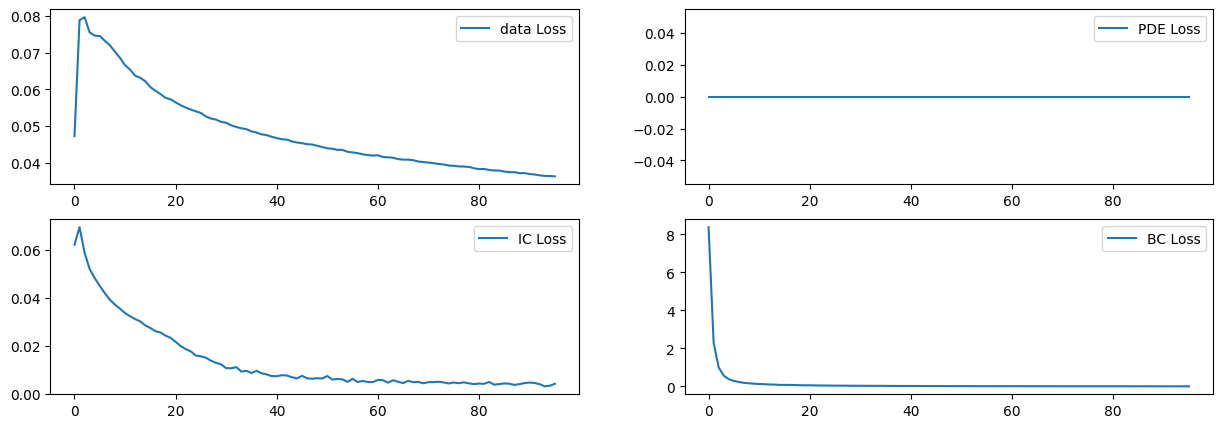

In [69]:
plt.figure(figsize=(15, 5))
plt.subplot(2, 2, 1)
plt.plot([epoch for epoch in range(len(data_loss_list))], data_loss_list, label="data Loss")
plt.legend()
plt.subplot(2, 2, 2)
plt.plot([epoch for epoch in range(len(pde_loss_list))], pde_loss_list, label="PDE Loss")
plt.legend()
plt.subplot(2, 2, 3)
plt.plot([epoch for epoch in range(len(ic_loss_list))], ic_loss_list, label="IC Loss")
plt.legend()
plt.subplot(2, 2, 4)
plt.plot([epoch for epoch in range(len(bc_loss_list))], bc_loss_list, label="BC Loss")
plt.legend()
plt.show()

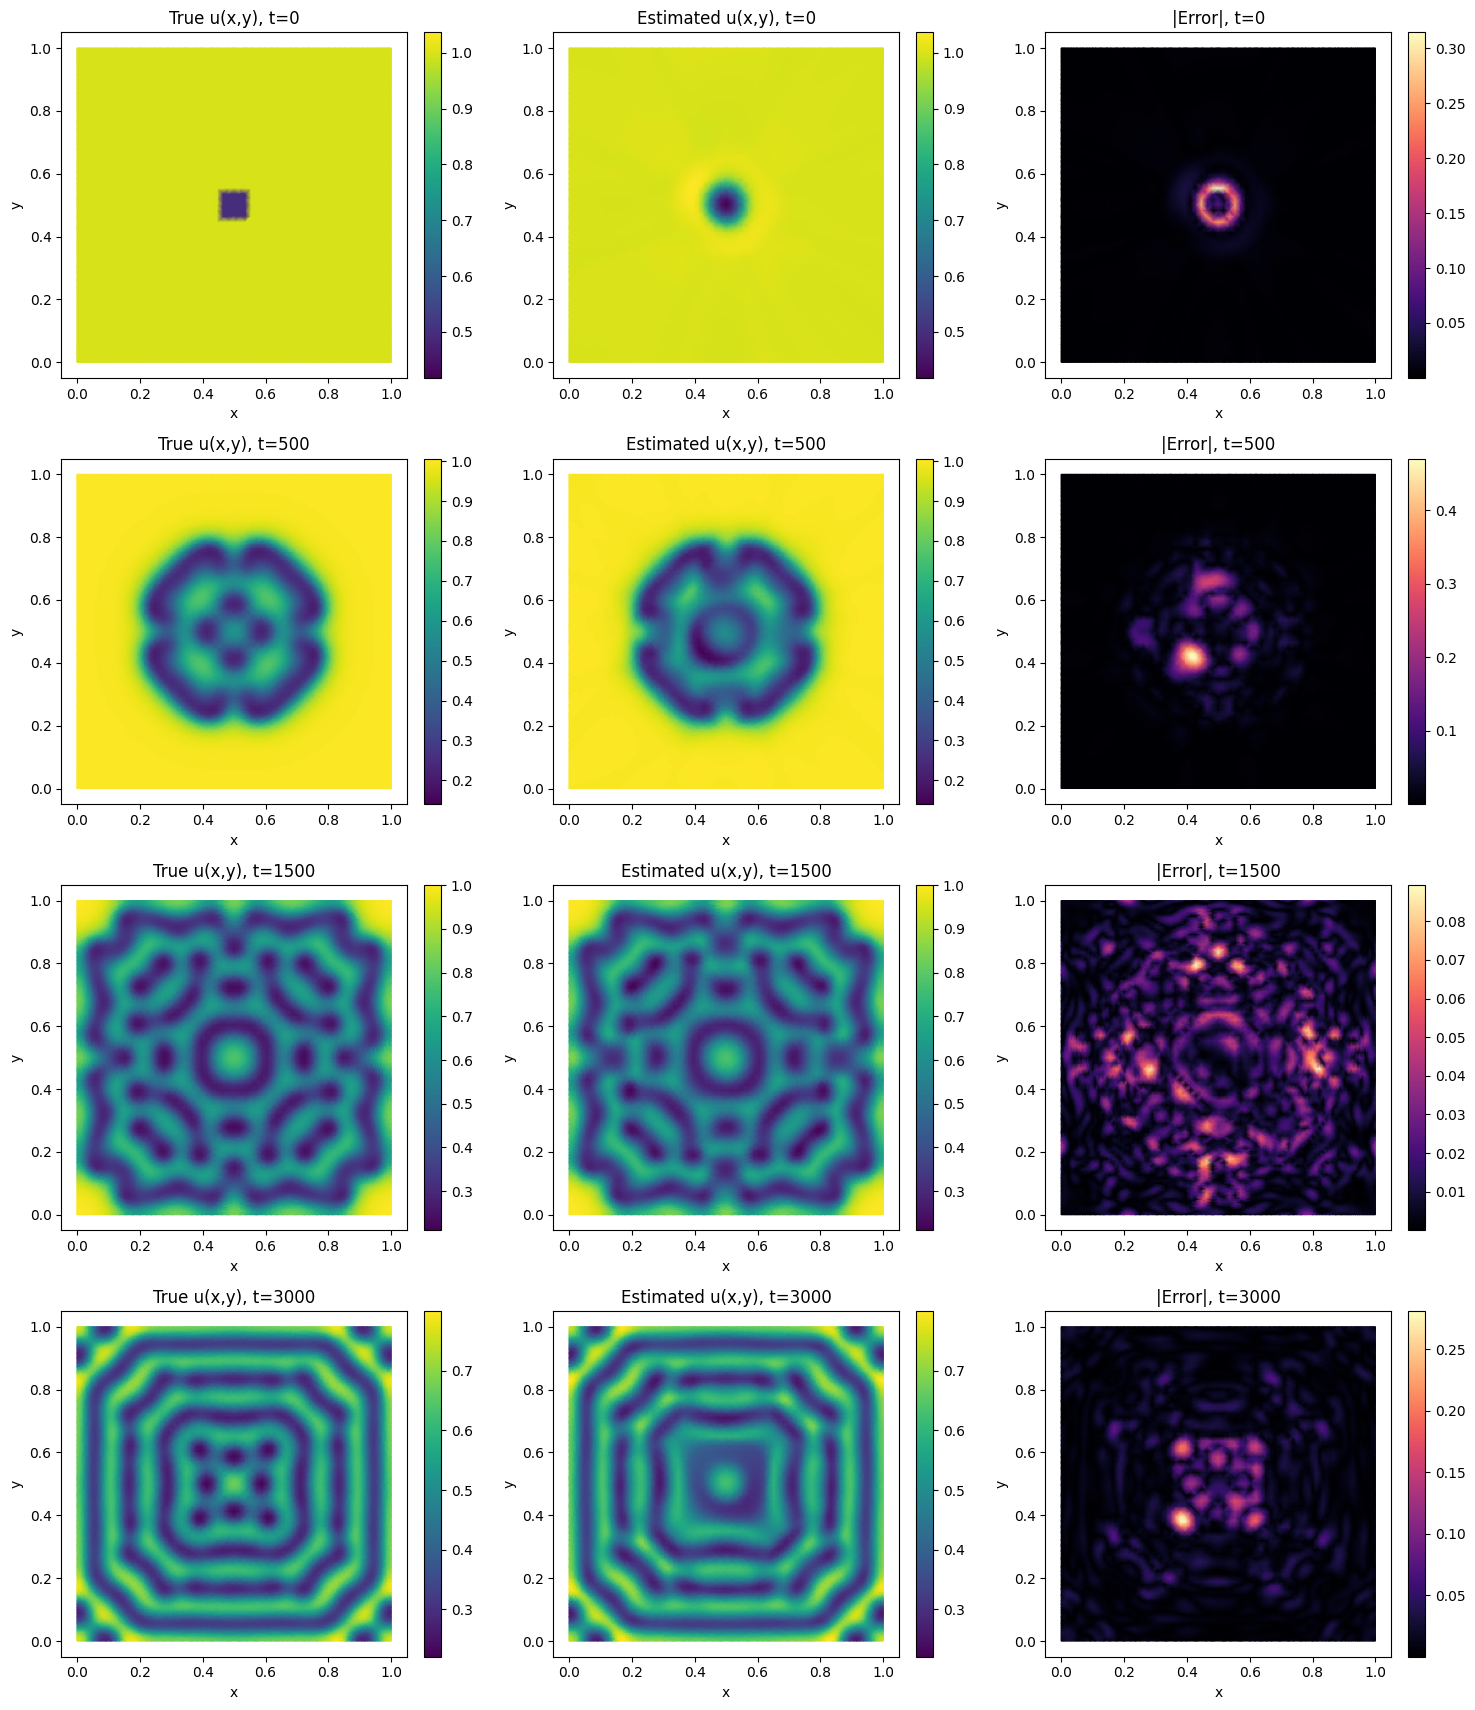

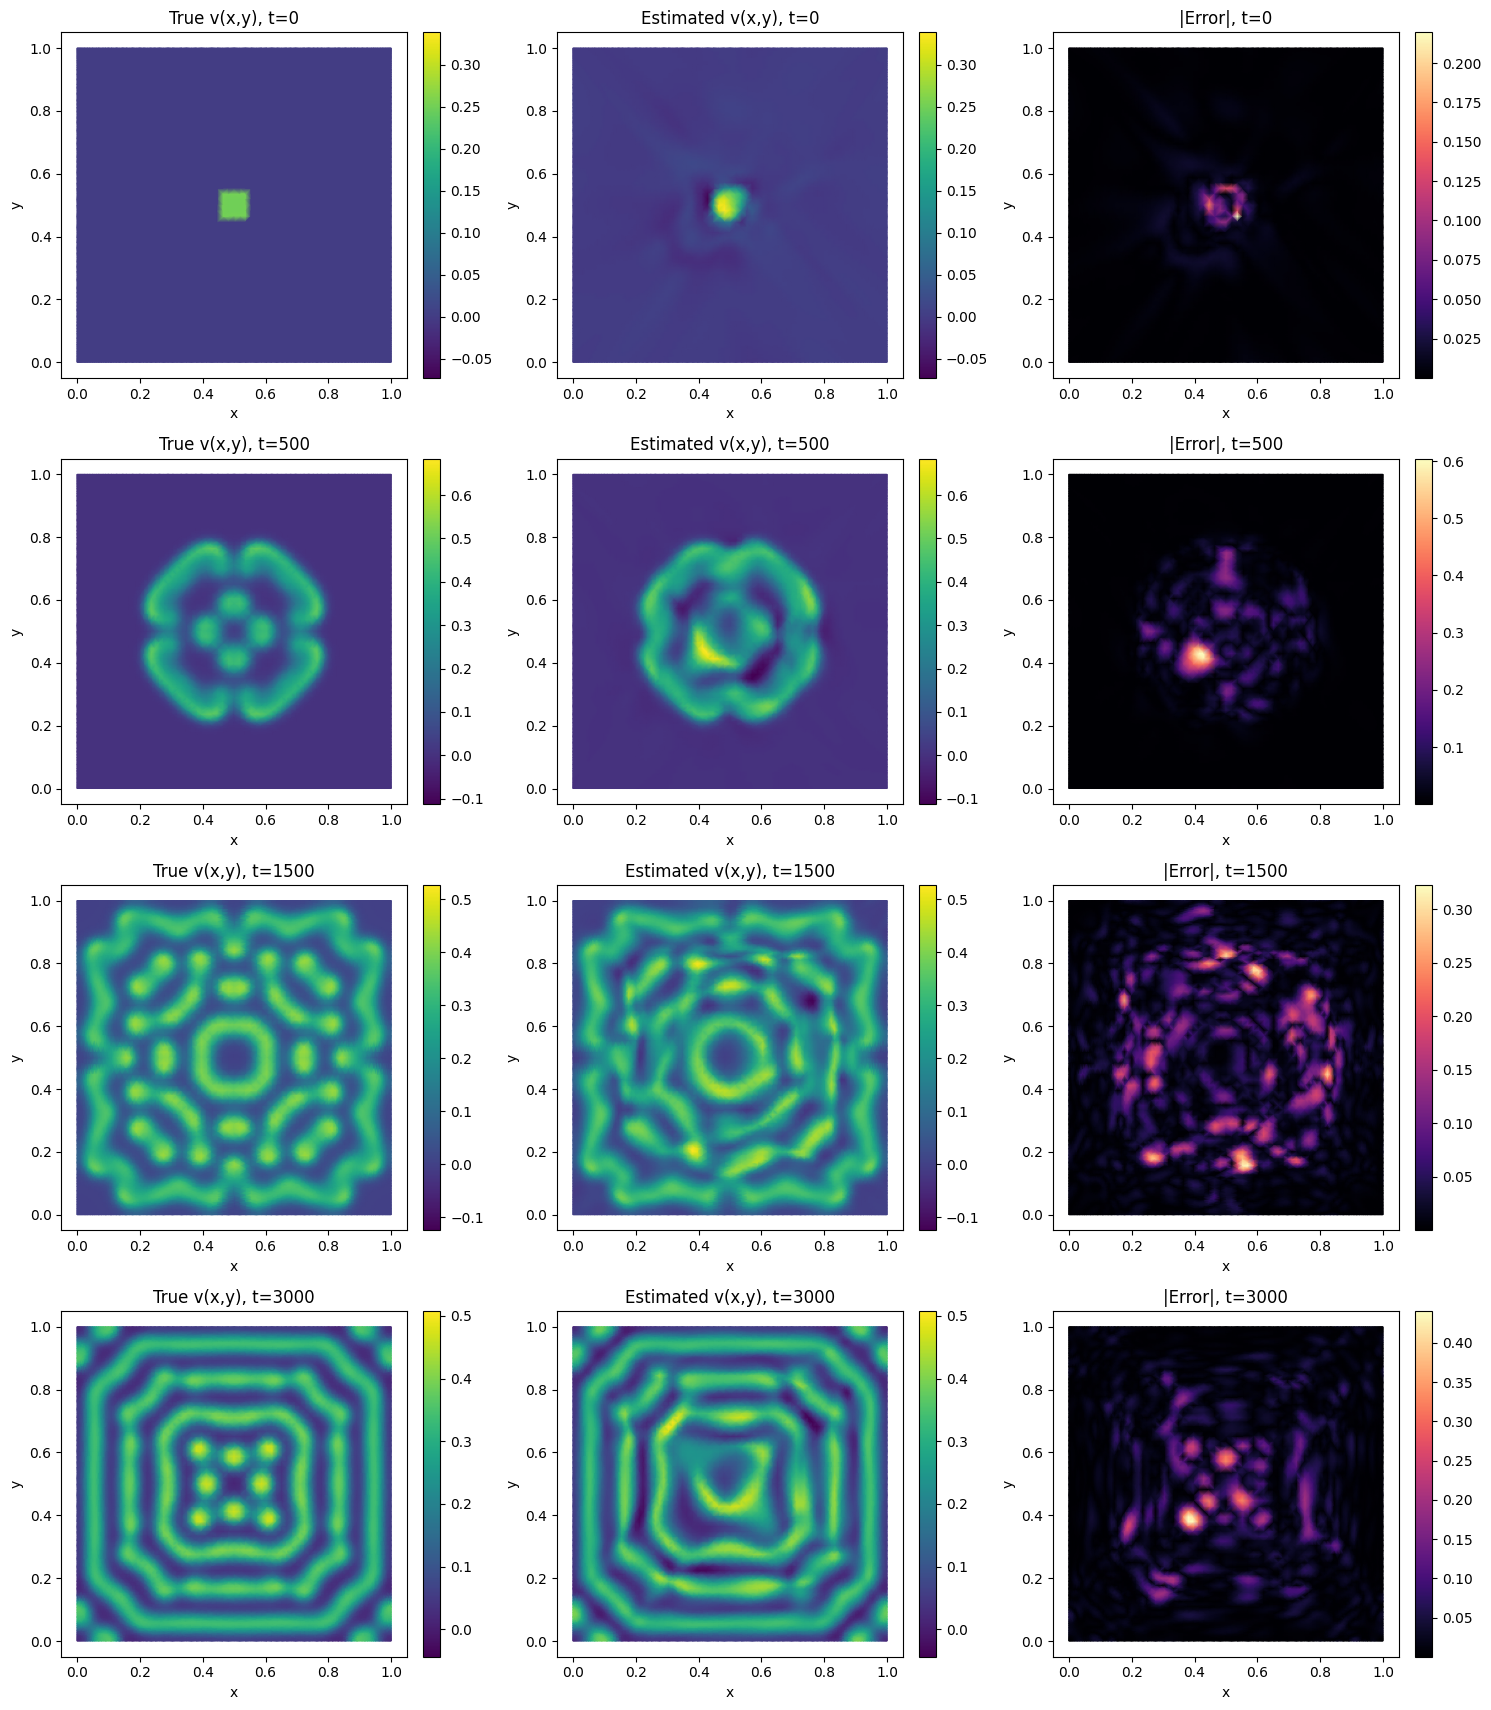

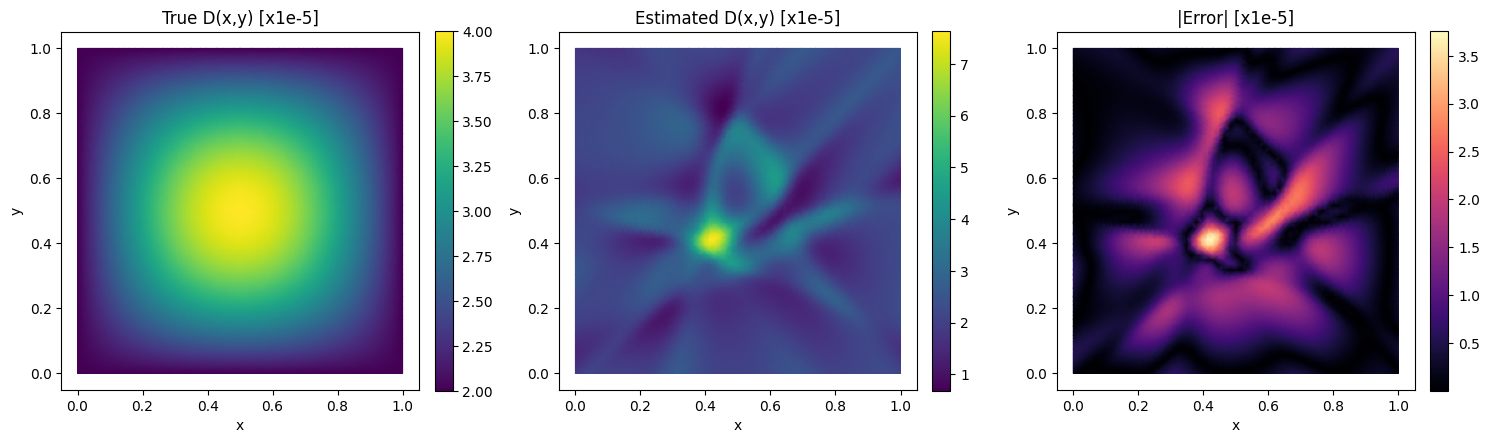

In [63]:
import matplotlib.tri as mtri

# ---------------------------------------------------------
# Settings
# ---------------------------------------------------------
plot_times = [0, 500, 1500, 3000]   # multiples of 10 in [0, 3000]

# True diffusion coefficients
D_true_fn = lambda x, y: 2e-5 * (1 + np.sin(np.pi * x) * np.sin(np.pi * y))
Dv_true = 1e-5

# ---------------------------------------------------------
# Mesh from the data
# ---------------------------------------------------------
x_all = df["x"].values
y_all = df["y"].values
triang = mtri.Triangulation(x_all, y_all)

x_t = torch.tensor(x_all, dtype=torch.float32, device=device).reshape(-1, 1)
y_t = torch.tensor(y_all, dtype=torch.float32, device=device).reshape(-1, 1)

# ---------------------------------------------------------
# Predictions
# ---------------------------------------------------------
@torch.no_grad()
def predict_uv(t_val):
    t_t = torch.full_like(x_t, float(t_val))
    X = torch.cat([
        normalize(x_t, x_min, x_max),
        normalize(y_t, y_min, y_max),
        normalize(t_t, t_min, t_max)
    ], dim=1)
    return u_nn(X).cpu().numpy().ravel(), v_nn(X).cpu().numpy().ravel()

@torch.no_grad()
def predict_D():
    X = torch.cat([
        normalize(x_t, x_min, x_max),
        normalize(y_t, y_min, y_max)
    ], dim=1)
    return Du_nn(X).cpu().numpy().ravel()

# ---------------------------------------------------------
# Heatmap helper
# ---------------------------------------------------------
def heat(ax, values, title, vmin=None, vmax=None, cmap="viridis"):
    cf = ax.tripcolor(triang, values, shading="gouraud", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    plt.colorbar(cf, ax=ax, fraction=0.046, pad=0.04)

# ---------------------------------------------------------
# u and v: true | estimated | |error|, one row per time
# ---------------------------------------------------------
preds = {t: predict_uv(t) for t in plot_times}

for field, idx in [("u", 0), ("v", 1)]:
    n = len(plot_times)
    fig, axes = plt.subplots(n, 3, figsize=(15, 4.3 * n), squeeze=False)

    for i, t in enumerate(plot_times):
        true = df[f"{field}_{t}"].values
        pred = preds[t][idx]
        err = np.abs(pred - true)

        vmin = min(true.min(), pred.min())
        vmax = max(true.max(), pred.max())

        heat(axes[i, 0], true, f"True {field}(x,y), t={t}", vmin, vmax)
        heat(axes[i, 1], pred, f"Estimated {field}(x,y), t={t}", vmin, vmax)
        heat(axes[i, 2], err,  f"|Error|, t={t}", cmap="magma")

    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# D(x,y): true | estimated | |error|
# ---------------------------------------------------------
D_est = predict_D()
D_true = D_true_fn(x_all, y_all)

share_scale = False   # set True once the estimate is in the right range

u0 = 1e-5   # plot in units of 1e-5
if share_scale:
    vmin = min(D_true.min(), D_est.min()) / u0
    vmax = max(D_true.max(), D_est.max()) / u0
    lim_true = lim_est = (vmin, vmax)
else:
    lim_true = (D_true.min() / u0, D_true.max() / u0)
    lim_est  = (None, None)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
heat(axes[0], D_true / u0, "True D(x,y) [x1e-5]", *lim_true)
heat(axes[1], D_est / u0,  "Estimated D(x,y) [x1e-5]", *lim_est)
heat(axes[2], np.abs(D_est - D_true) / u0, "|Error| [x1e-5]", cmap="magma")
plt.tight_layout()
plt.show()

Saving the model

In [ ]:
import os

save_dir = "/content/drive/MyDrive/gray_scott_data/checkpoints"
os.makedirs(save_dir, exist_ok=True)

checkpoint = {
    "u_nn":  u_nn.state_dict(),
    "v_nn":  v_nn.state_dict(),
    "Du_nn": Du_nn.state_dict(),
    "Dv_nn": Dv_nn.state_dict(),        # contains Dv_raw
    "optimizer": optimizer.state_dict(),
    "epoch": epoch + 1,                 # last finished epoch
    "D_SCALE": D_SCALE,
}

torch.save(checkpoint, os.path.join(save_dir, "pinn_checkpoint_01.pt"))
print("Saved to", os.path.join(save_dir, "pinn_checkpoint.pt"))